# Damascus Stock Market Forecasting

This notebook documents the cleaned, time-ordered evaluation of the bundled Damascus Securities Exchange dataset. The target is the **UIC closing price at the next available market session**. Saved outputs below correspond to a fresh run of the included pipeline on the bundled CSV.

> Research and coursework project. Forecasts are not investment advice.


In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "src" / "forecast.py").exists():
    ROOT = ROOT.parent
if not (ROOT / "src" / "forecast.py").exists():
    raise FileNotFoundError("Open this notebook from the repository root or its notebooks/ folder.")
sys.path.insert(0, str(ROOT))
from src.forecast import FEATURES, TARGET, evaluate, load_market_data, make_next_session_dataset, save_results

DATA_PATH = ROOT / "data" / "raw" / "dse_market_data.csv"
RESULTS_DIR = ROOT / "results"
print(f"Repository: {ROOT}")
print(f"Source dataset: {DATA_PATH.relative_to(ROOT)}")

Repository: .
Source dataset: data/raw/dse_market_data.csv


## 1. Load and inspect the supplied data

The source file is preserved as supplied. The analysis parses dates and numeric fields, sorts rows by date, and retains the last source row when a date is repeated. The fixed feature list also prevents existing `pred*` columns from being used as model inputs.

In [2]:
raw = pd.read_csv(DATA_PATH)
market = load_market_data(DATA_PATH)
parsed_dates = pd.to_datetime(raw["Date"], format="mixed", errors="coerce")
duplicate_rows = int(parsed_dates.duplicated(keep="last").sum())
print(f"Source rows: {len(raw):,}")
print(f"Rows after date cleanup and duplicate removal: {len(market):,}")
print(f"Repeated-date rows removed: {duplicate_rows}")
print(f"Date range: {market['Date'].min().date()} to {market['Date'].max().date()}")
print(f"Model features ({len(FEATURES)}): {', '.join(FEATURES)}")

Source rows: 1,614
Rows after date cleanup and duplicate removal: 1,613
Repeated-date rows removed: 1
Date range: 2018-01-02 to 2024-11-24
Model features (16): DWX, DLX, ALAQ, NIC, SII, SKI, UIC, gold, oil, AROP, SYP, TC, NC, TD, ND, ^IRX


### Preview the cleaned market table

In [3]:
market[["Date", "UIC", "DWX", "DLX", "gold", "oil"]].head(5)

Date,UIC,DWX,DLX,gold,oil
2018-01-02,479.0,5954.93,0.0,1249.199951,59.610001
2018-01-03,479.0,5907.15,0.0,1247.400024,60.279999
2018-01-04,479.0,5904.72,0.0,1237.000000,61.450001
2018-01-07,479.0,5849.22,0.0,1242.699951,60.150002
2018-01-08,479.0,5822.30,0.0,1244.400024,60.200001


## 2. Data quality and descriptive statistics

This table checks missing values, exact zeroes, and the range of each model feature after preprocessing. Zeroes are retained as values from the source; they are not silently recoded as missing data. The COVID indicators and some market fields contain many zeroes, so their meaning should be verified before treating them as ordinary continuous measurements.

In [4]:
quality = pd.DataFrame({
    "feature": FEATURES,
    "missing": [int(market[c].isna().sum()) for c in FEATURES],
    "zero_values": [int((market[c] == 0).sum()) for c in FEATURES],
    "zero_share_pct": [float((market[c] == 0).mean() * 100) for c in FEATURES],
    "distinct_values": [int(market[c].nunique()) for c in FEATURES],
    "min": [float(market[c].min()) for c in FEATURES],
    "median": [float(market[c].median()) for c in FEATURES],
    "max": [float(market[c].max()) for c in FEATURES],
})
display(quality.round(2))

feature,missing,zero_values,zero_share_pct,distinct_values,min,median,max
DWX,0,0,0.00,1608,5430.56,10221.38,101697.17
DLX,0,244,15.13,1320,0.00,1454.45,14331.69
ALAQ,0,0,0.00,738,273.84,607.50,7977.87
NIC,0,0,0.00,134,312.50,511.50,9048.00
SII,0,0,0.00,100,269.00,491.28,4499.75
SKI,0,0,0.00,115,338.25,594.29,5834.35
UIC,0,0,0.00,194,380.22,507.50,5858.80
gold,0,0,0.00,1448,1176.20,1775.80,2433.90
oil,0,0,0.00,1430,19.33,73.62,127.98
AROP,0,0,0.00,100,269.00,491.28,4499.75


## 3. Define the next-session target

For each dated row *t*, the features come from that market session. The target is UIC’s closing price on the **next available market date**, not the next calendar day. Rows are sorted before shifting, and the final row has no future target, so it is omitted.

In [5]:
aligned = market[["Date", TARGET]].copy()
aligned["target_date"] = aligned["Date"].shift(-1)
aligned["target_UIC"] = aligned[TARGET].shift(-1)
aligned = aligned.dropna(subset=["target_date", "target_UIC"]).head(5)
aligned["Date"] = aligned["Date"].dt.strftime("%Y-%m-%d")
aligned["target_date"] = aligned["target_date"].dt.strftime("%Y-%m-%d")
display(aligned.rename(columns={"Date": "feature_date", "UIC": "current_UIC"}))

feature_date,current_UIC,target_date,target_UIC
2018-01-02,479.0,2018-01-03,479.0
2018-01-03,479.0,2018-01-04,479.0
2018-01-04,479.0,2018-01-07,479.0
2018-01-07,479.0,2018-01-08,479.0
2018-01-08,479.0,2018-01-09,479.0


## 4. Inspect the historical UIC series

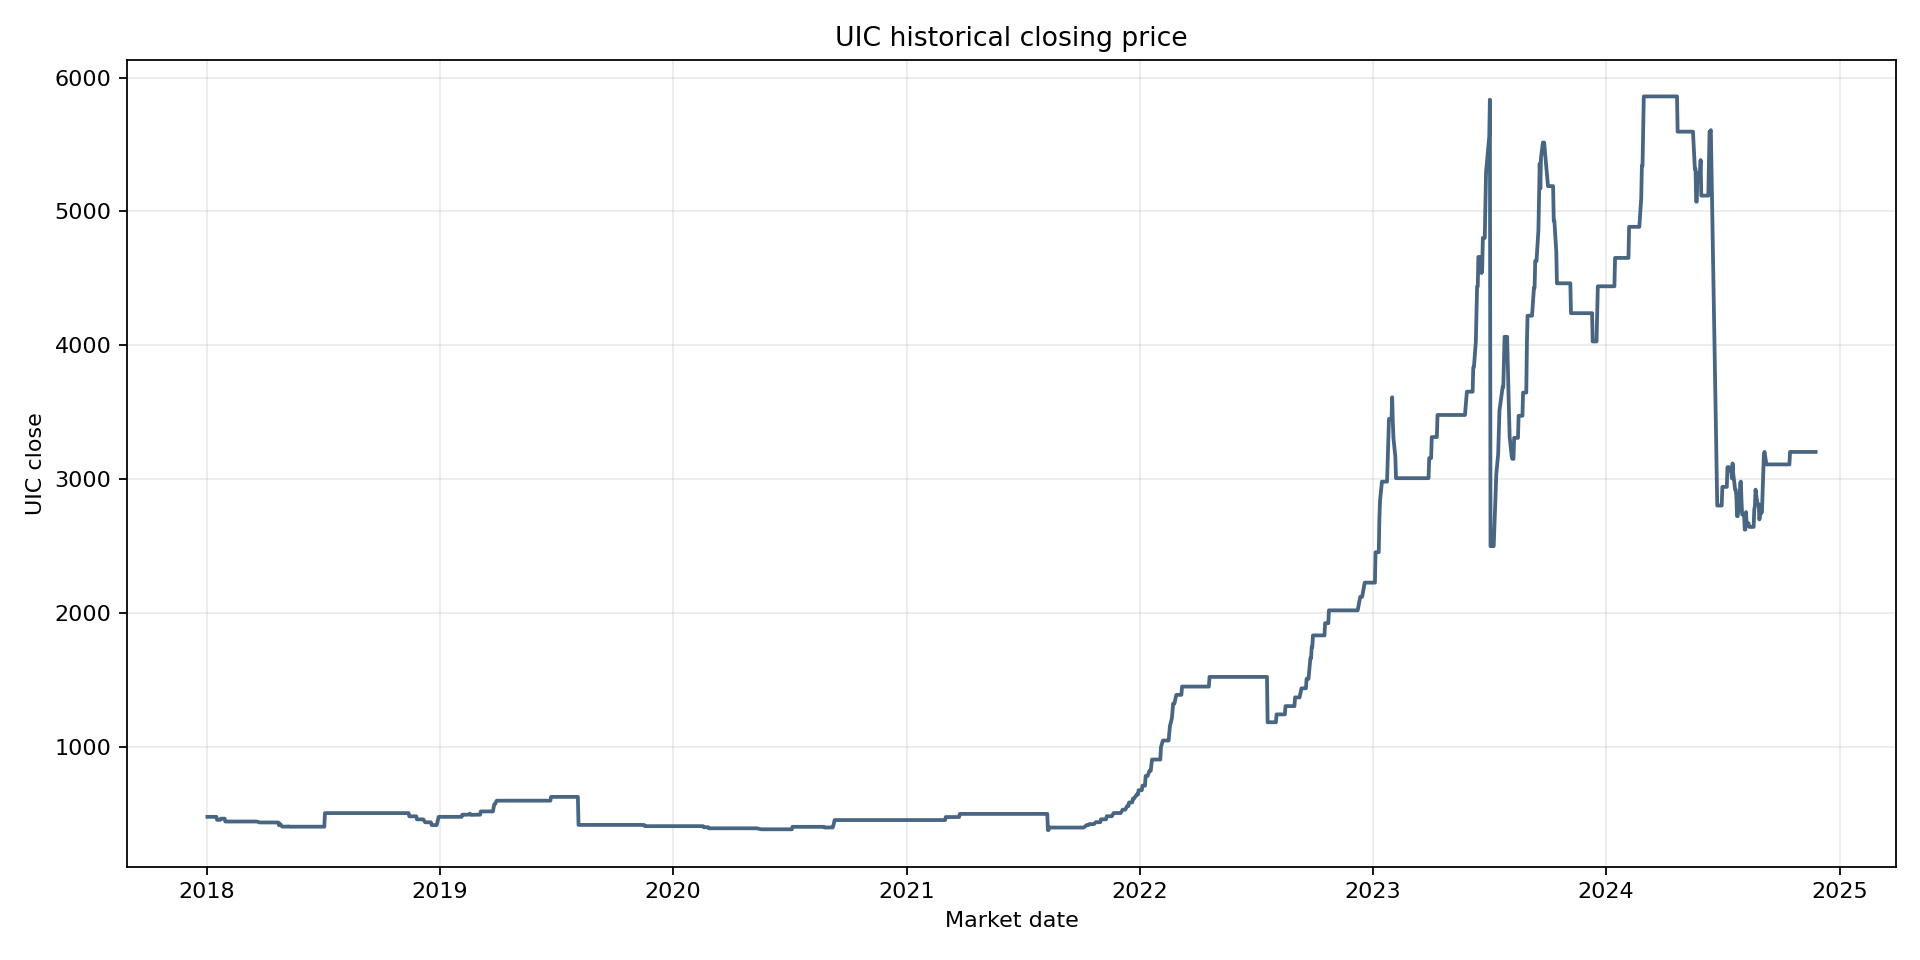

In [6]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(market["Date"], market[TARGET], color="#486581", linewidth=1.7)
ax.set(title="UIC historical closing price", xlabel="Market date", ylabel="UIC close")
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

## 5. UIC changes and volatility

Price levels can move over time and obscure the distribution of session-to-session changes. This section summarizes UIC percentage changes and plots their distribution alongside a 30-session rolling standard deviation. The rolling measure describes historical variability; it is not a volatility forecast.

observations,mean_pct,median_pct,std_pct,p05_pct,p95_pct,minimum_pct,maximum_pct
1612,0.17,0.0,2.819,0.0,4.945,-57.143,25.0


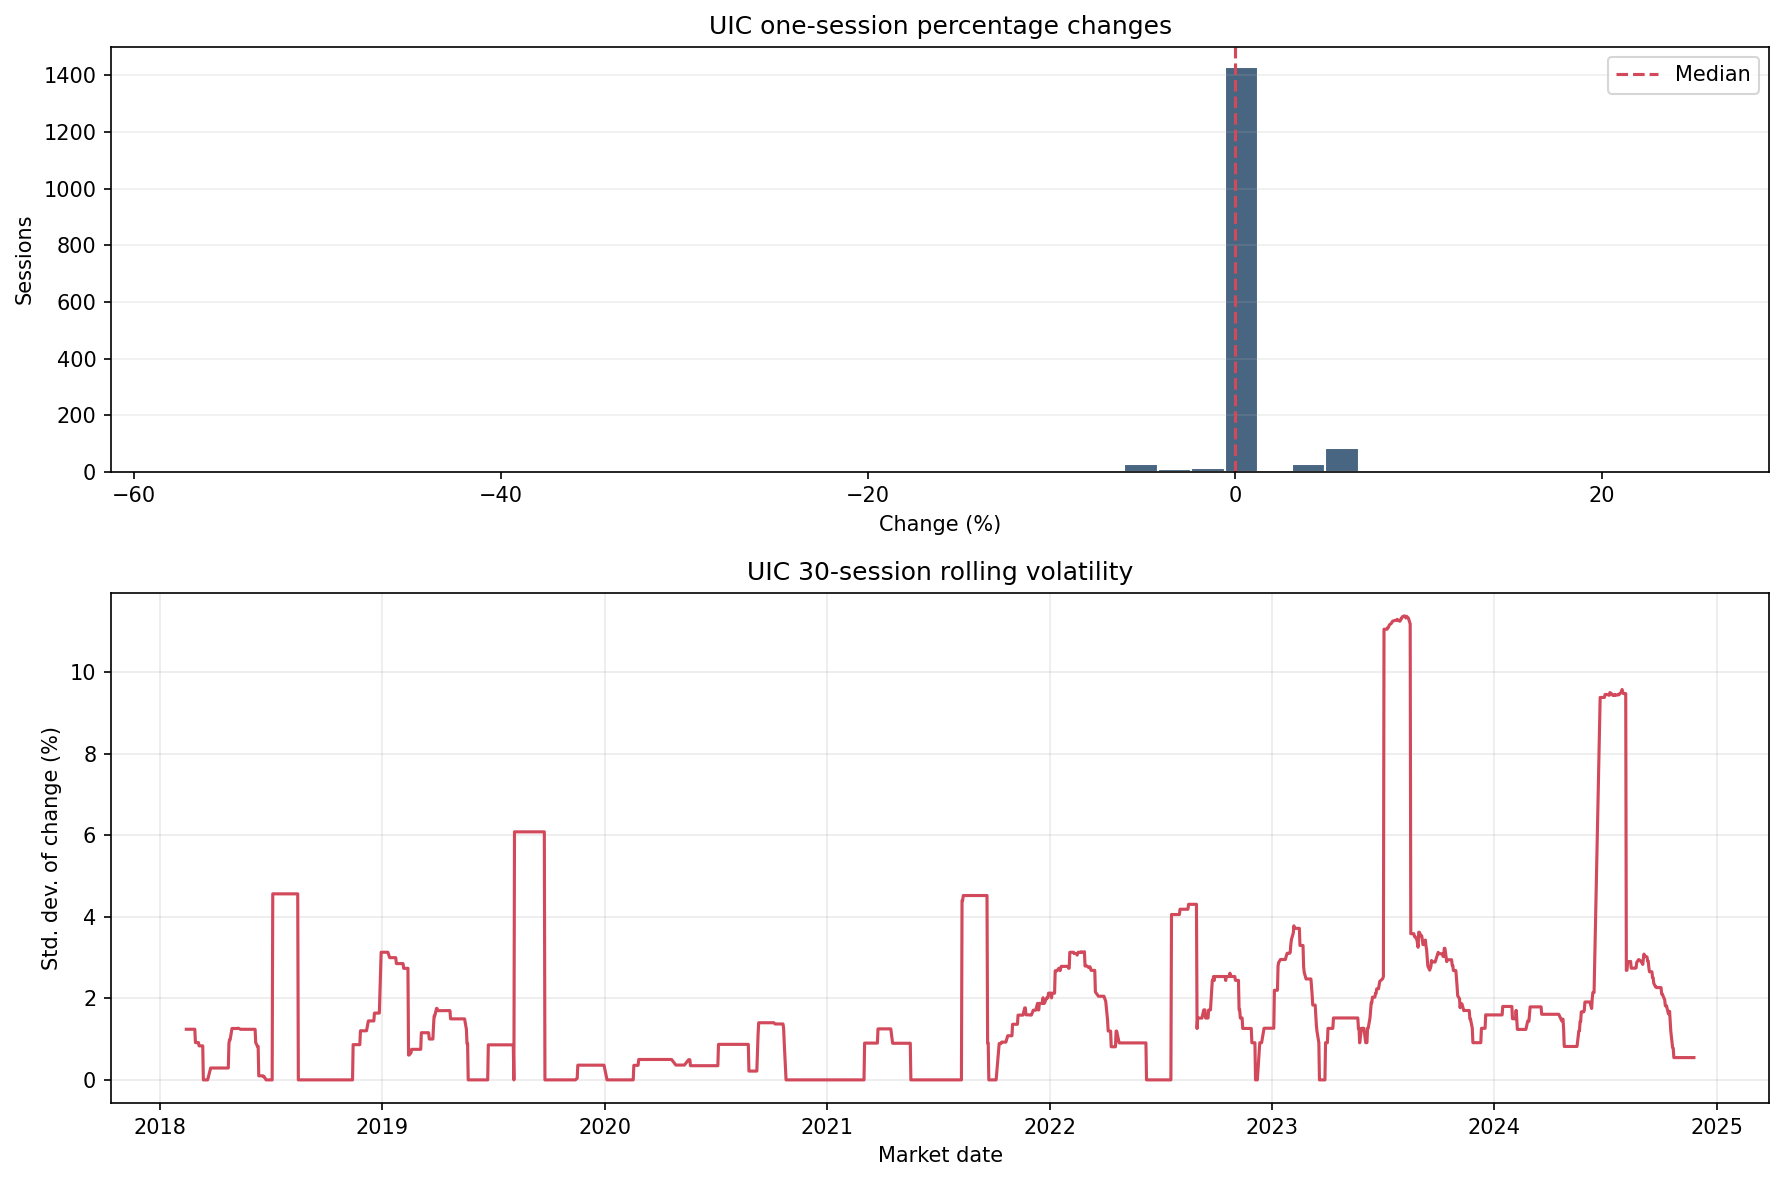

In [7]:
uic_returns = market[TARGET].pct_change(fill_method=None).mul(100).dropna()
return_summary = pd.DataFrame([{
    "observations": int(uic_returns.size),
    "mean_pct": uic_returns.mean(),
    "median_pct": uic_returns.median(),
    "std_pct": uic_returns.std(),
    "p05_pct": uic_returns.quantile(0.05),
    "p95_pct": uic_returns.quantile(0.95),
    "minimum_pct": uic_returns.min(),
    "maximum_pct": uic_returns.max(),
}])
display(return_summary.round(3))
rolling_vol = uic_returns.rolling(30).std()
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), gridspec_kw={"height_ratios": [1, 1.2]})
ax1.hist(uic_returns, bins=45, color="#486581", edgecolor="white")
ax1.axvline(uic_returns.median(), color="#d1495b", linestyle="--", label="Median")
ax1.set(title="UIC one-session percentage changes", xlabel="Change (%)", ylabel="Sessions")
ax1.legend()
ax1.grid(axis="y", alpha=0.2)
ax2.plot(market["Date"].iloc[1:], rolling_vol, color="#d1495b", linewidth=1.5)
ax2.set(title="UIC 30-session rolling volatility", xlabel="Market date", ylabel="Std. dev. of change (%)")
ax2.grid(alpha=0.25)
fig.tight_layout()
plt.show()

## 6. Reproduce the supplied heatmap: Pearson correlation of levels

The supplied “Correlation Heatmap (Cleaned Data)” is reproduced from the cleaned feature **levels** using Pearson correlation. This matches the calculation that produced the strong positive relationships in the report image. For example, the level correlation between UIC and SYP is about 0.93.

High correlations between trending price levels can arise because several series move over the same period. They describe co-movement in this historical sample; they do not establish causation or prove that one feature predicts the next-session target.

feature,pearson_corr_with_UIC
SYP,0.934
TC,0.928
SKI,0.912
TD,0.908
DWX,0.881
AROP,0.868
SII,0.868
DLX,0.867
NIC,0.840
^IRX,0.829


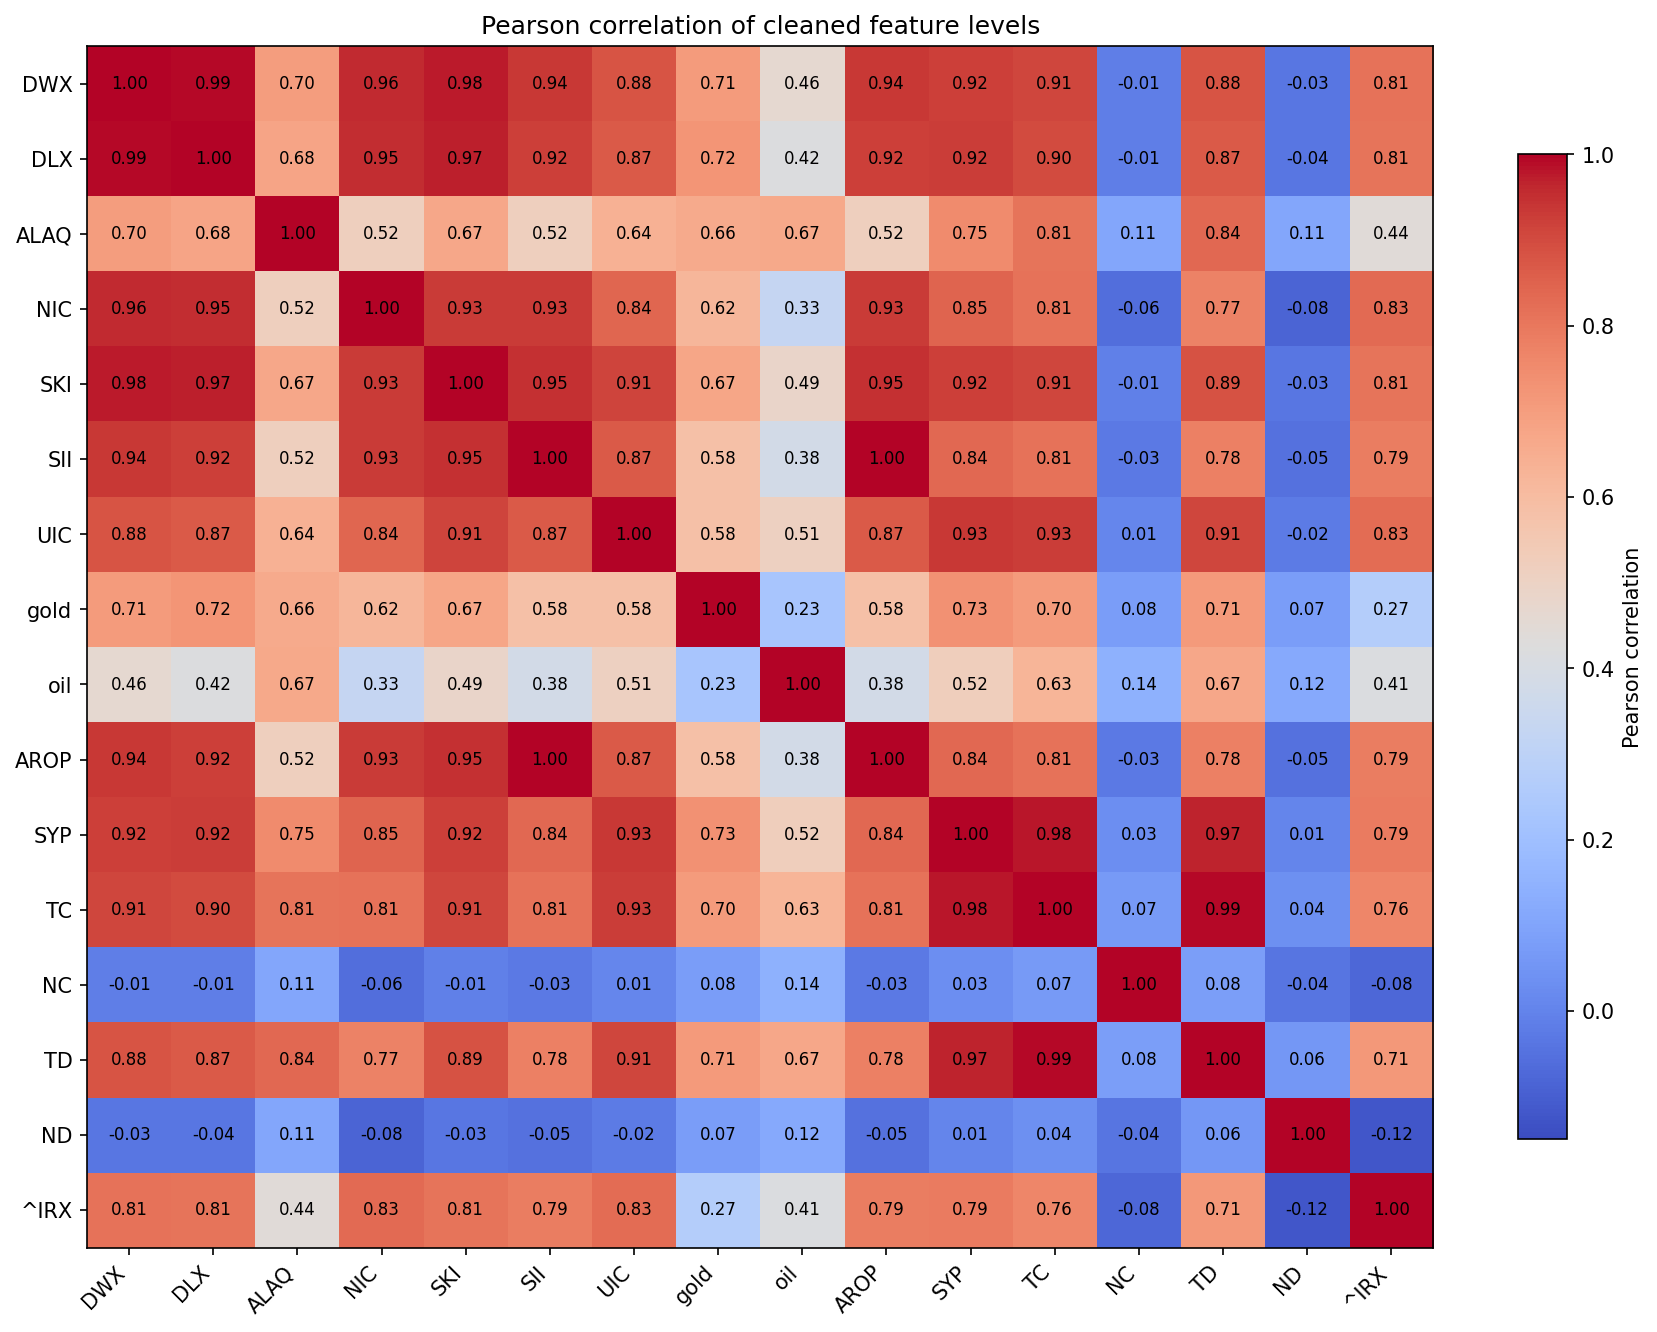

In [8]:
# Pearson correlation on the cleaned feature levels, matching the supplied report heatmap.
heatmap_features = ["DWX", "DLX", "ALAQ", "NIC", "SKI", "SII", "UIC", "gold", "oil", "AROP", "SYP", "TC", "NC", "TD", "ND", "^IRX"]
level_corr = market[heatmap_features].corr(method="pearson")

uic_level_corr = level_corr[TARGET].drop(TARGET)
uic_level_corr = uic_level_corr.sort_values(key=lambda values: values.abs(), ascending=False)
uic_level_corr = uic_level_corr.rename("pearson_corr_with_UIC").reset_index().rename(columns={"index": "feature"})
display(uic_level_corr.round(3))

fig, ax = plt.subplots(figsize=(12, 9))
image = ax.imshow(level_corr, cmap="coolwarm", vmin=-0.15, vmax=1, aspect="auto")
ax.set_xticks(range(len(heatmap_features)), labels=heatmap_features, rotation=45, ha="right")
ax.set_yticks(range(len(heatmap_features)), labels=heatmap_features)
ax.set_title("Pearson correlation of cleaned feature levels")
for row in range(len(heatmap_features)):
    for col in range(len(heatmap_features)):
        ax.text(col, row, f"{level_corr.iloc[row, col]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(image, ax=ax, label="Pearson correlation", shrink=0.82)
fig.tight_layout()
plt.show()

## 7. Use a chronological holdout

The first 80% of the usable dated examples form the training set, and the final 20% form the holdout. The split preserves time order. This is one holdout evaluation, not a rolling backtest.

In [9]:
X, y, target_dates = make_next_session_dataset(market)
split_at = int(len(X) * 0.8)
print(f"Usable next-session examples: {len(X):,}")
print(f"Training examples: {split_at:,}")
print(f"Holdout examples: {len(X) - split_at:,}")
print(f"Training target dates: {target_dates.iloc[0].date()} to {target_dates.iloc[split_at - 1].date()}")
print(f"Holdout target dates: {target_dates.iloc[split_at].date()} to {target_dates.iloc[-1].date()}")

Usable next-session examples: 1,612
Training examples: 1,289
Holdout examples: 323
Training target dates: 2018-01-03 to 2023-07-13
Holdout target dates: 2023-07-16 to 2024-11-24


## 8. Fit and compare models

The pipeline compares Linear Regression, Random Forest, and an MLP with a simple persistence baseline: predict that the next UIC close will equal the current UIC close. XGBoost is optional and was not installed for the packaged run.

In [10]:
metrics, predictions = evaluate(market)
save_results(market, metrics, predictions)
display(metrics.round(4))
print(f"Holdout observations: {len(predictions):,}")
if "XGBoost" not in metrics["model"].tolist():
    print("XGBoost not run; install requirements-optional.txt to include it.")

model,MAE,RMSE,R2
Persistence baseline,48.1997,179.2298,0.9692
Linear regression,507.2084,558.4440,0.7012
Random forest,502.3295,612.7767,0.6403
MLP,1158.9645,1396.6273,-0.8686


Holdout observations: 323
XGBoost not run; install requirements-optional.txt to include it.


### First eight holdout predictions

In [11]:
display(predictions.head(8).round(2))

target_date,actual_UIC,persistence_baseline,Linear regression,Random forest,MLP
2023-07-16,3188.00,3037.00,3010.46,3193.72,3421.64
2023-07-17,3347.00,3188.00,3143.93,3416.57,3487.59
2023-07-18,3514.00,3347.00,3282.60,3801.35,3551.31
2023-07-23,3689.00,3514.00,3429.27,3779.21,3622.18
2023-07-24,3689.00,3689.00,3582.29,3786.17,3692.67
2023-07-25,3873.00,3689.00,3585.36,3798.22,3706.07
2023-07-26,4063.82,3873.00,3771.04,3838.76,3597.80
2023-07-27,4063.82,4063.82,3928.81,4140.82,3668.80


### Visual comparison on the holdout

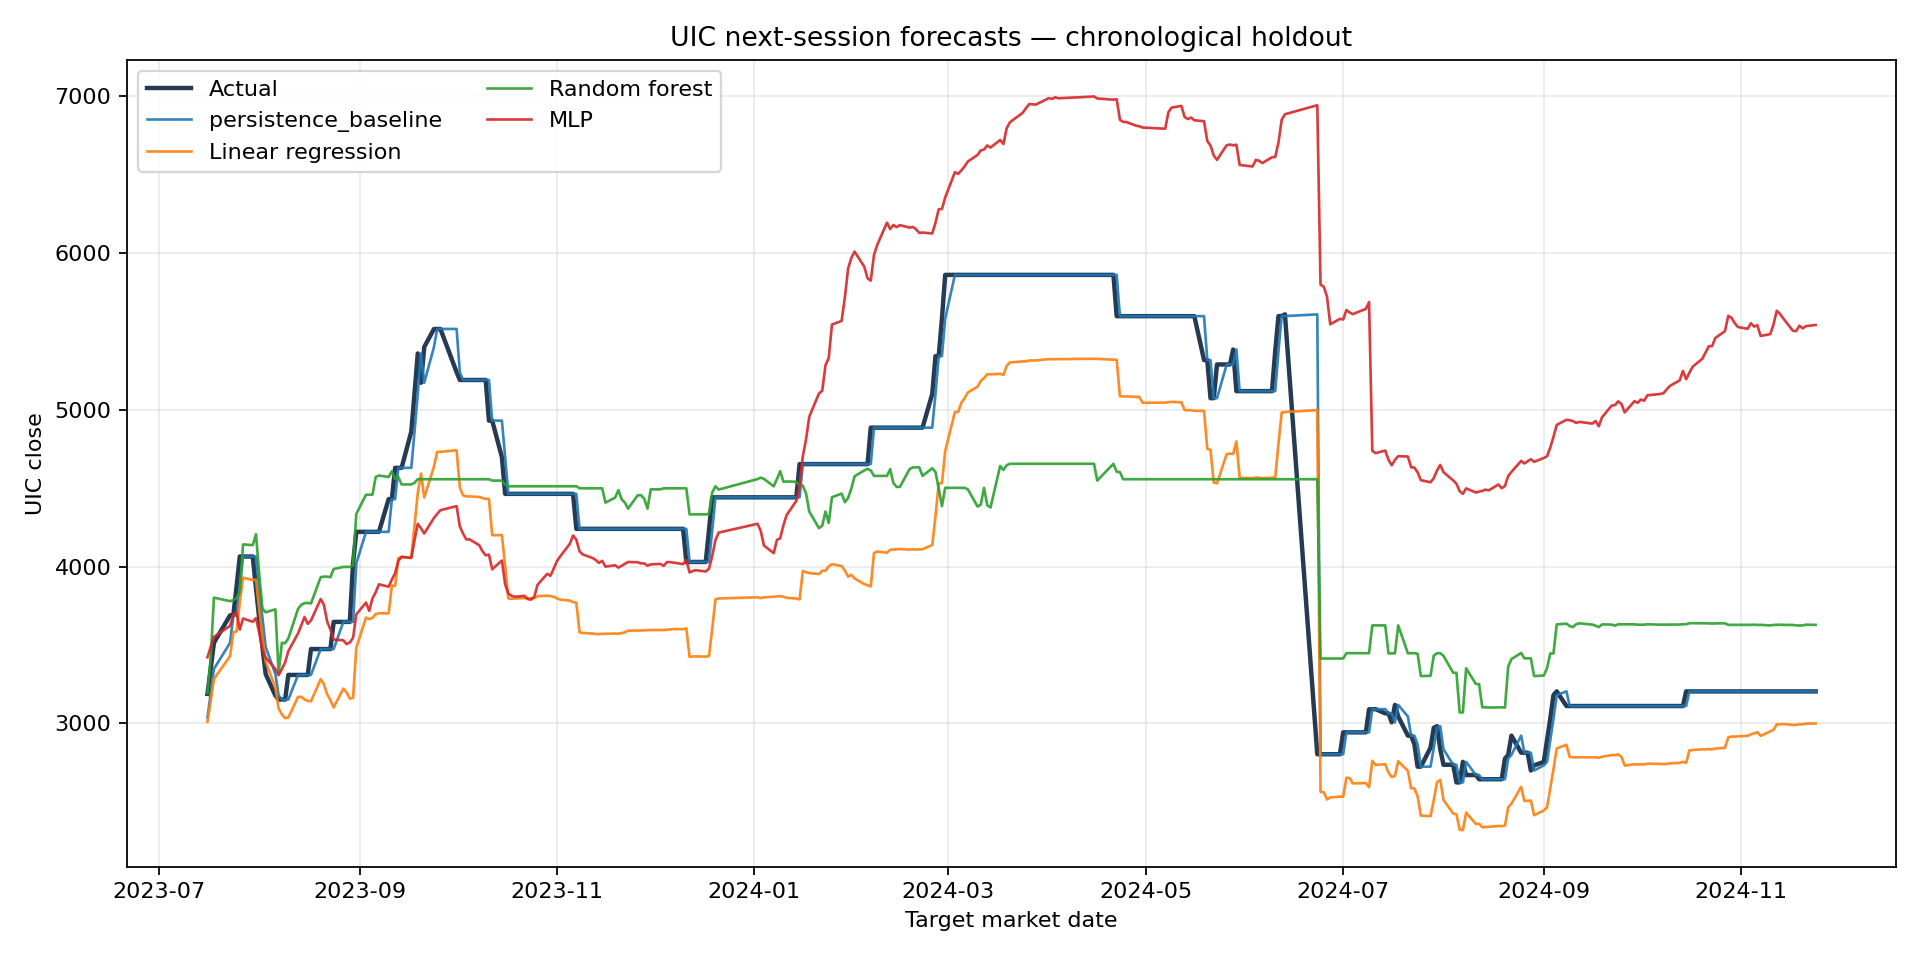

In [12]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(predictions["target_date"], predictions["actual_UIC"], label="Actual", color="#243b53", linewidth=2)
for name in ["persistence_baseline", "Linear regression", "Random forest", "XGBoost", "MLP"]:
    if name in predictions.columns:
        ax.plot(predictions["target_date"], predictions[name], label=name, linewidth=1.2, alpha=0.9)
ax.set(title="UIC next-session forecasts — chronological holdout", xlabel="Target market date", ylabel="UIC close")
ax.legend(ncol=2)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

## 9. Interpretation and limitations

In this run, the persistence baseline has the lowest MAE and RMSE. The tested fitted regressors therefore do not demonstrate predictive improvement over carrying forward the current UIC close. The MLP’s negative R² indicates that it performs poorly relative to predicting the holdout mean under the R² definition.

These results are an initial evaluation only: one historical holdout, one target ticker, no rolling backtest, and no transaction costs or trading simulation. They should not be presented as evidence of a profitable strategy. The original coursework report contains results from earlier experiments; its scores use a different setup and are not the results shown here.

In [13]:
for name in ["chronological_holdout_metrics.csv", "chronological_holdout_predictions.csv", "uic_historical_price.png", "chronological_holdout_forecasts.png"]:
    path = RESULTS_DIR / name
    print(f"{path.relative_to(ROOT)} — {'present' if path.exists() else 'not generated'}")

results/chronological_holdout_metrics.csv — present
results/chronological_holdout_predictions.csv — present
results/uic_historical_price.png — present
results/chronological_holdout_forecasts.png — present
